# **Week 14 Cross-Sport Analysis**

AGAINST ALL ODDS — WEEK 14
CROSS-SPORT ANALYSIS AND FINAL PROJECT
Missing inputs:
 - week13_unpredictability_index.csv
 - week13_abstention_coverage_results.csv
 - week13_predict_caution_abstain_results.csv
Upload the missing CSV files or a ZIP containing Week 13 results.


Saving Week 13 Zip File.zip to Week 13 Zip File.zip

Inputs:
 - week13_unpredictability_index.csv -> /content/week14_inputs/week13_unpredictability_index.csv
 - week13_abstention_coverage_results.csv -> /content/week14_inputs/week13_abstention_coverage_results.csv
 - week13_predict_caution_abstain_results.csv -> /content/week14_inputs/week13_predict_caution_abstain_results.csv


,sport,display_name,test_games,full_coverage_accuracy,full_coverage_error_rate,mean_fragility_score,median_fragility_score,mean_unpredictability_index,median_unpredictability_index,mean_error_risk_probability,mean_model_disagreement,accuracy_at_60pct_coverage,accuracy_gain_at_60pct_coverage,best_accuracy_gain_from_abstention,coverage_for_best_accuracy_gain
0,NBA,NBA,1209,0.689826,0.310174,63.564930,68.75,47.249446,47.850,0.491616,0.192721,0.752066,0.062240,0.062240,0.6
1,NFL,NFL,255,0.639216,0.360784,62.230392,62.50,48.198471,46.410,0.478542,0.368627,0.679739,0.040523,0.040523,0.6
2,Premier League,Soccer (Premier League),370,0.624324,0.375676,60.760135,68.75,48.278568,48.235,0.494527,0.302703,0.684685,0.060360,0.060360,0.6



Final research answers:


,question,answer,basis,value
0,Which sport is easiest to predict?,NBA,Highest full-coverage TEST accuracy.,0.689826
1,Which sport is hardest to predict?,Soccer (Premier League),Lowest full-coverage TEST accuracy.,0.624324
2,Which sport has the most fragile predictions?,NBA,Highest mean Fragility Score.,63.564930
3,Which sport benefits most from abstention?,NBA,Largest accuracy gain at the common 60% covera...,0.062240
4,Which factor creates the most instability over...,Probability uncertainty,Largest mean 0–100 Unpredictability component.,66.535502
5,Are prediction errors/upsets concentrated amon...,Yes. All three sports show prediction-error co...,Top 25% risk group compared with its share of ...,1.000000


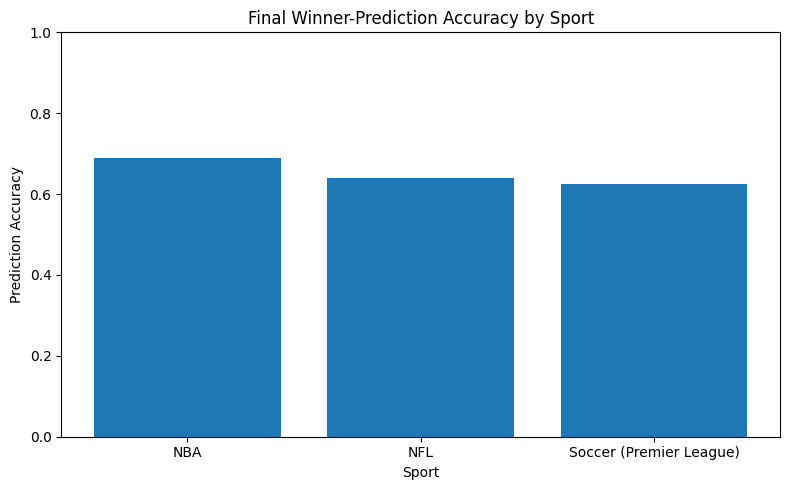

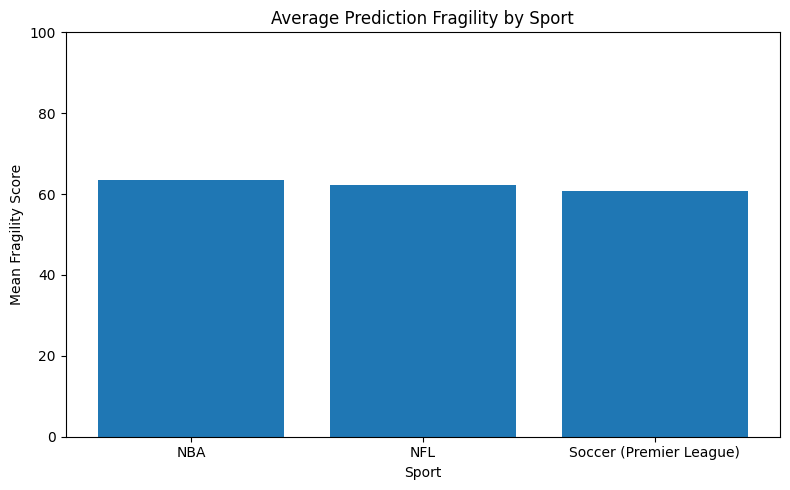

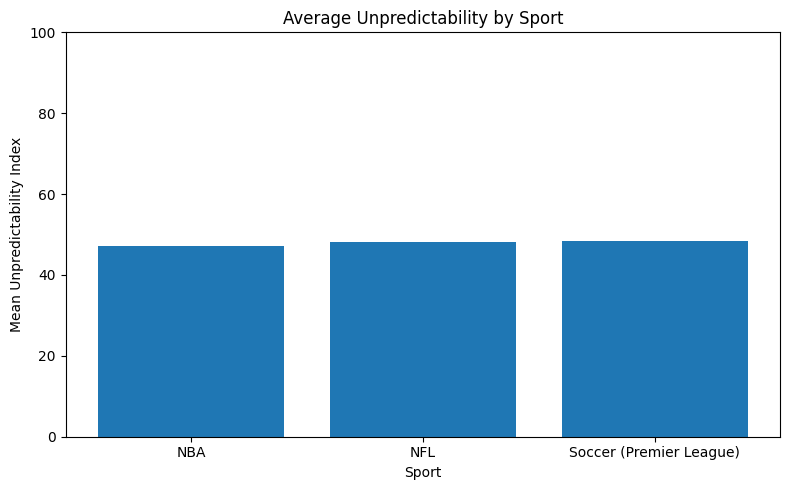

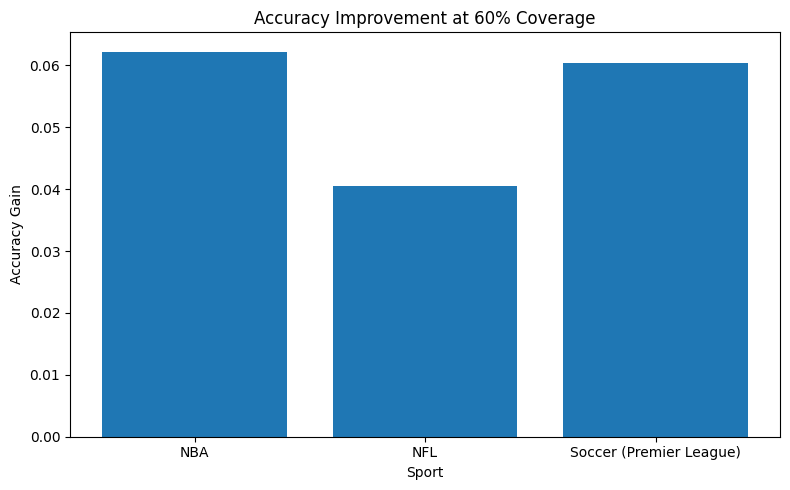

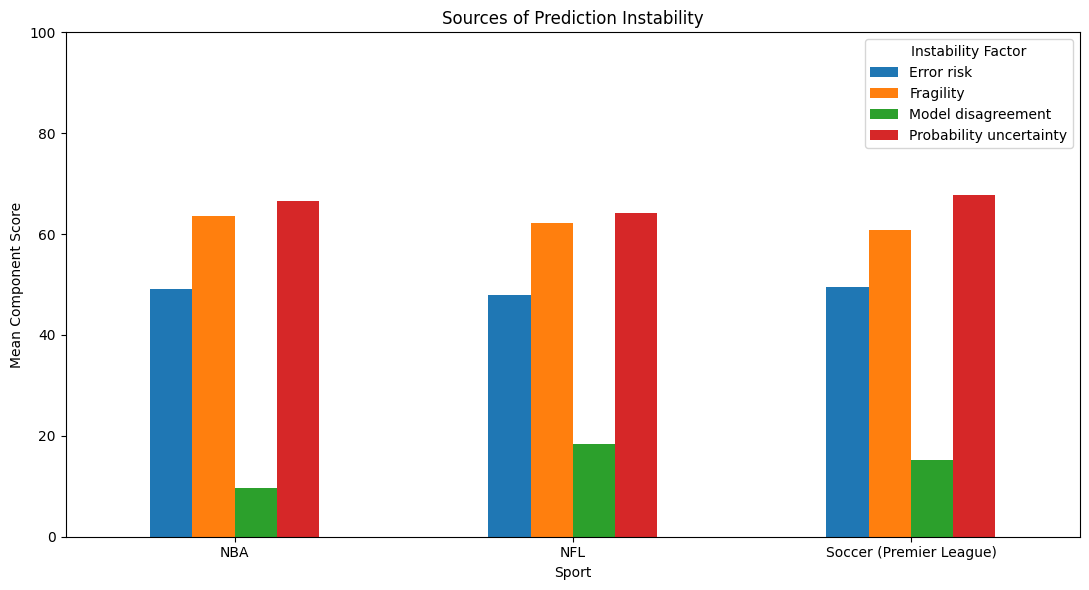

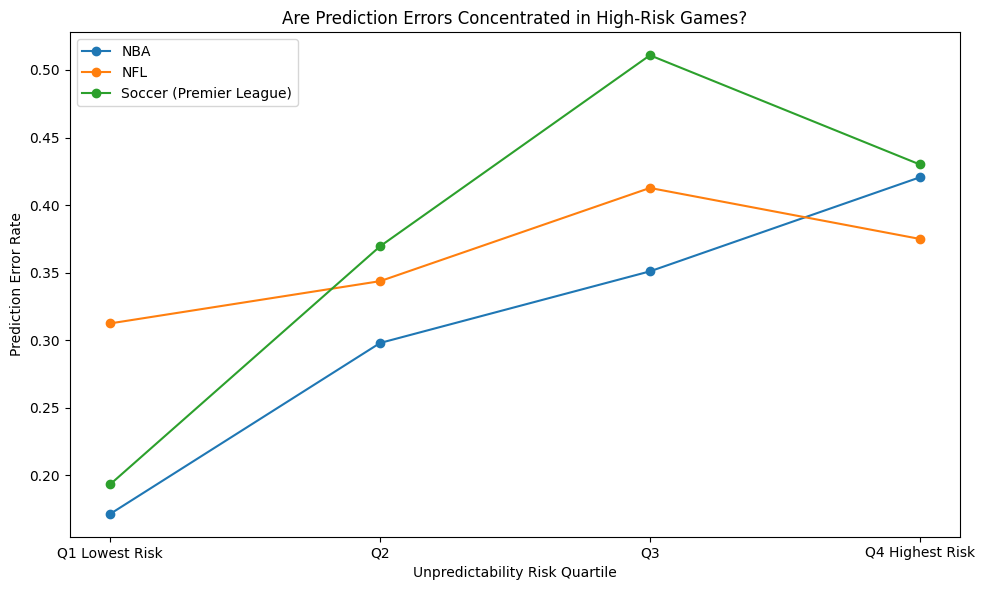

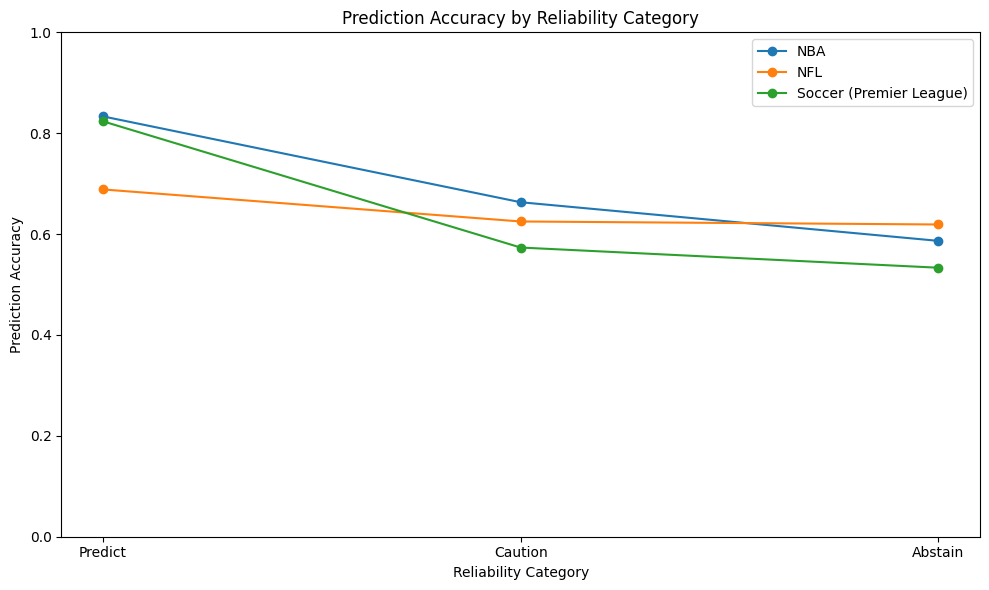

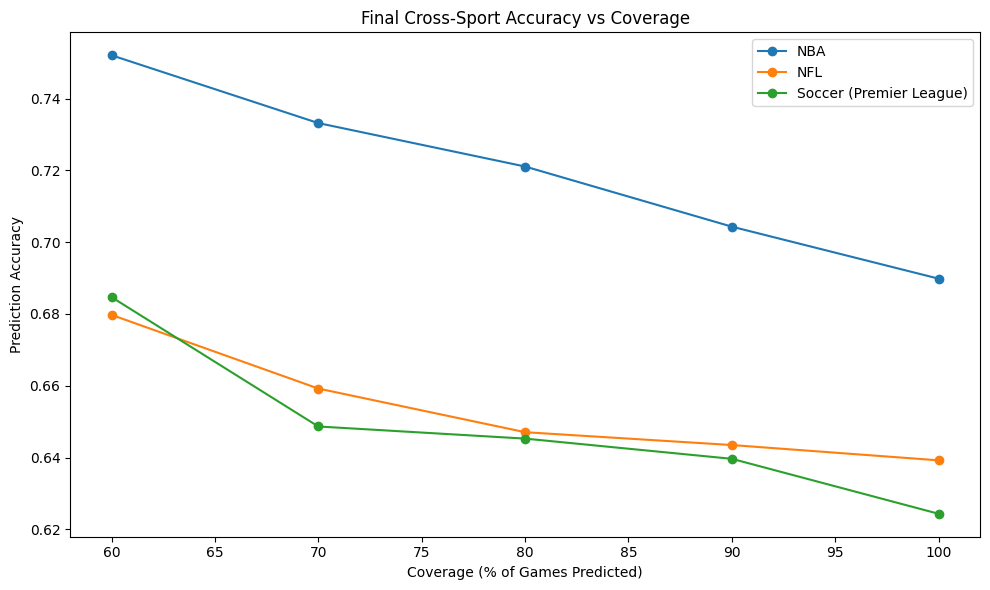


Final project file audit:


,artifact_type,filename,found,path_if_found
0,notebook,07_feature_engineering.ipynb,False,
1,notebook,08_baseline_models.ipynb,False,
2,notebook,09_logistic_regression.ipynb,False,
3,notebook,10_elo_model.ipynb,False,
4,notebook,11_gradient_boosting.ipynb,False,
5,notebook,12_calibration.ipynb,False,
6,notebook,13_fragility_analysis.ipynb,False,
7,notebook,14_error_risk_model.ipynb,False,
8,notebook,15_unpredictability_index.ipynb,False,
9,notebook,16_abstention_analysis.ipynb,False,



Reminder: manually rerun every notebook from beginning to end before final submission.

Week 14 quality checks:


,check,passed
0,three_sports_analyzed,True
1,six_questions_answered,True
2,accuracy_valid,True
3,fragility_valid,True
4,unpredictability_valid,True
5,high_risk_three_sports,True
6,figures_created,True
7,docs_created,True



AGAINST ALL ODDS — WEEK 14 COMPLETE
✅ Cross-sport accuracy compared
✅ Fragility compared
✅ Unpredictability compared
✅ Abstention performance compared
✅ Six final research questions answered
✅ High-risk error concentration tested
✅ Final figures and documentation created
✅ Final project artifact audit created
✅ GitHub upload ZIP created

IMPORTANT: Rerun every notebook from beginning to end before final submission.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, sys, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(x): print(x)

warnings.filterwarnings('ignore', category=FutureWarning)
np.random.seed(42)

PROJECT_TITLE = 'Against All Odds'
SPORTS = ['NBA', 'NFL', 'Premier League']
DISPLAY = {'NBA':'NBA','NFL':'NFL','Premier League':'Soccer (Premier League)'}
INDEX_INPUT = 'week13_unpredictability_index.csv'
COVERAGE_INPUT = 'week13_abstention_coverage_results.csv'
CATEGORY_INPUT = 'week13_predict_caution_abstain_results.csv'
COMPONENTS = {
    'CALIBRATED_UNCERTAINTY_COMPONENT':'Probability uncertainty',
    'FRAGILITY_COMPONENT':'Fragility',
    'ERROR_RISK_COMPONENT':'Error risk',
    'MODEL_DISAGREEMENT_COMPONENT':'Model disagreement',
}

print('='*78)
print('AGAINST ALL ODDS — WEEK 14')
print('CROSS-SPORT ANALYSIS AND FINAL PROJECT')
print('='*78)


def in_colab():
    return 'google.colab' in sys.modules


def choose_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd if cwd.name.lower().replace('_','-') in {'againstallodds','against-all-odds'} else None,
        Path('/content/againstallodds'), Path('/content/Against-All-Odds'),
        Path('/content/drive/MyDrive/againstallodds'), Path('/content/drive/MyDrive/Against-All-Odds')
    ]
    for p in candidates:
        if p is not None and p.exists():
            return p
    return Path('/content/againstallodds') if in_colab() else cwd/'againstallodds'


ROOT = choose_root()
RESULTS = ROOT/'results'
FIGURES = ROOT/'figures'/'week14'
DOCS = ROOT/'docs'
for d in [RESULTS, FIGURES, DOCS]: d.mkdir(parents=True, exist_ok=True)


def search_locations():
    locs = [ROOT, RESULTS, Path('/content'), Path('/content/week14_inputs'), Path.cwd().resolve()]
    return list(dict.fromkeys([p for p in locs if p.exists()]))


def find_file(name):
    for r in search_locations():
        p = r/name
        if p.exists(): return p
    for r in search_locations():
        try:
            m = list(r.rglob(name))
        except (PermissionError, OSError):
            m = []
        if m: return m[0]
    return None


def locate_required():
    names = [INDEX_INPUT, COVERAGE_INPUT, CATEGORY_INPUT]
    found = {n:find_file(n) for n in names}
    missing = [n for n,p in found.items() if p is None]
    if missing and in_colab():
        print('Missing inputs:', *missing, sep='\n - ')
        print('Upload the missing CSV files or a ZIP containing Week 13 results.')
        from google.colab import files
        uploaded = files.upload()
        udir = Path('/content/week14_inputs'); udir.mkdir(parents=True, exist_ok=True)
        for n,b in uploaded.items():
            p = udir/Path(n).name; p.write_bytes(b)
            if zipfile.is_zipfile(p):
                with zipfile.ZipFile(p,'r') as z: z.extractall(udir)
        found = {n:find_file(n) for n in names}
    missing = [n for n,p in found.items() if p is None]
    if missing:
        raise FileNotFoundError('Run Week 13 first or upload:\n'+'\n'.join(missing))
    return found


FILES = locate_required()
print('\nInputs:')
for n,p in FILES.items(): print(' -',n,'->',p)

idx = pd.read_csv(FILES[INDEX_INPUT], dtype={'game_id':'string'})
cov = pd.read_csv(FILES[COVERAGE_INPUT])
cat = pd.read_csv(FILES[CATEGORY_INPUT])
for df in [idx,cov,cat]:
    df['sport'] = df['sport'].astype('string').str.strip()

req_idx = ['sport','game_id','HOME_WIN','WINNER_PREDICTION','WINNER_PREDICTION_CORRECT',
           'PRIMARY_MODEL_ERROR','FRAGILITY_SCORE','UNPREDICTABILITY_INDEX',
           'RELIABILITY_CATEGORY','ERROR_RISK_PROBABILITY','MODEL_DISAGREEMENT_COUNT'] + list(COMPONENTS)
req_cov = ['sport','requested_coverage','prediction_accuracy','prediction_error_rate','accuracy_improvement_vs_100pct']
req_cat = ['sport','RELIABILITY_CATEGORY','games','prediction_accuracy','prediction_error_rate','mean_unpredictability_index']
for name,df,cols in [('index',idx,req_idx),('coverage',cov,req_cov),('category',cat,req_cat)]:
    miss = [c for c in cols if c not in df.columns]
    if miss: raise ValueError(f'{name} input missing columns: {miss}')

if set(idx.sport.unique()) != set(SPORTS): raise ValueError('Index must contain NBA, NFL, Premier League.')
if idx.game_id.duplicated().any(): raise ValueError('Duplicate game_id values in Week 13 index.')

for c in ['WINNER_PREDICTION_CORRECT','PRIMARY_MODEL_ERROR','FRAGILITY_SCORE','UNPREDICTABILITY_INDEX',
          'ERROR_RISK_PROBABILITY','MODEL_DISAGREEMENT_COUNT'] + list(COMPONENTS):
    idx[c] = pd.to_numeric(idx[c], errors='coerce')

# ------------------------------------------------------------
# 1. Main cross-sport summary
# ------------------------------------------------------------
summary = []
for sport in SPORTS:
    s = idx[idx.sport.eq(sport)].copy()
    sc = cov[cov.sport.eq(sport)].copy()
    c100 = sc[np.isclose(sc.requested_coverage,1.0)]
    c60 = sc[np.isclose(sc.requested_coverage,0.6)]
    if c100.empty or c60.empty: raise ValueError(f'{sport}: need 100% and 60% coverage rows.')
    a100 = float(c100.prediction_accuracy.iloc[0]); a60 = float(c60.prediction_accuracy.iloc[0])
    lower = sc[sc.requested_coverage < 1.0]
    best = lower.sort_values('accuracy_improvement_vs_100pct', ascending=False).iloc[0]
    summary.append({
        'sport':sport, 'display_name':DISPLAY[sport], 'test_games':len(s),
        'full_coverage_accuracy':float(s.WINNER_PREDICTION_CORRECT.mean()),
        'full_coverage_error_rate':float(s.PRIMARY_MODEL_ERROR.mean()),
        'mean_fragility_score':float(s.FRAGILITY_SCORE.mean()),
        'median_fragility_score':float(s.FRAGILITY_SCORE.median()),
        'mean_unpredictability_index':float(s.UNPREDICTABILITY_INDEX.mean()),
        'median_unpredictability_index':float(s.UNPREDICTABILITY_INDEX.median()),
        'mean_error_risk_probability':float(s.ERROR_RISK_PROBABILITY.mean()),
        'mean_model_disagreement':float(s.MODEL_DISAGREEMENT_COUNT.mean()),
        'accuracy_at_60pct_coverage':a60,
        'accuracy_gain_at_60pct_coverage':a60-a100,
        'best_accuracy_gain_from_abstention':float(best.accuracy_improvement_vs_100pct),
        'coverage_for_best_accuracy_gain':float(best.requested_coverage),
    })
summary = pd.DataFrame(summary)
SUMMARY_PATH = RESULTS/'week14_cross_sport_summary.csv'; summary.to_csv(SUMMARY_PATH,index=False)
display(summary)

# ------------------------------------------------------------
# 2. Final questions
# ------------------------------------------------------------
easiest = summary.sort_values(['full_coverage_accuracy','mean_unpredictability_index'], ascending=[False,True]).iloc[0]
hardest = summary.sort_values(['full_coverage_accuracy','mean_unpredictability_index'], ascending=[True,False]).iloc[0]
fragile = summary.sort_values('mean_fragility_score', ascending=False).iloc[0]
abstain = summary.sort_values('accuracy_gain_at_60pct_coverage', ascending=False).iloc[0]

# ------------------------------------------------------------
# 3. Sources of instability
# ------------------------------------------------------------
comp_rows = []
for sport in SPORTS:
    s = idx[idx.sport.eq(sport)]
    for col,label in COMPONENTS.items():
        comp_rows.append({'sport':sport,'factor':label,'component_column':col,'mean_component_score':float(s[col].mean())})
component_summary = pd.DataFrame(comp_rows)
overall_factors = pd.DataFrame([
    {'factor':label,'component_column':col,'mean_component_score':float(idx[col].mean())}
    for col,label in COMPONENTS.items()
]).sort_values('mean_component_score', ascending=False).reset_index(drop=True)
COMP_PATH = RESULTS/'week14_instability_factor_summary.csv'; component_summary.to_csv(COMP_PATH,index=False)
OVERALL_PATH = RESULTS/'week14_overall_instability_factors.csv'; overall_factors.to_csv(OVERALL_PATH,index=False)
top_factor = overall_factors.iloc[0]

# Fragility drivers
if 'FRAGILITY_DRIVER' in idx.columns:
    drivers = idx[idx.FRAGILITY_DRIVER.notna()].groupby(['sport','FRAGILITY_DRIVER']).size().reset_index(name='games_where_feature_flipped_prediction_first')
    if not drivers.empty:
        totals = drivers.groupby('sport').games_where_feature_flipped_prediction_first.transform('sum')
        drivers['share_of_first_flips'] = drivers.games_where_feature_flipped_prediction_first/totals
else:
    drivers = pd.DataFrame(columns=['sport','FRAGILITY_DRIVER','games_where_feature_flipped_prediction_first','share_of_first_flips'])
DRIVER_PATH = RESULTS/'week14_fragility_driver_summary.csv'; drivers.to_csv(DRIVER_PATH,index=False)

# ------------------------------------------------------------
# 4. High-risk error concentration
# ------------------------------------------------------------
hr_rows, bucket_frames = [], []
for sport in SPORTS:
    s = idx[idx.sport.eq(sport)].copy().sort_values(['UNPREDICTABILITY_INDEX','game_id'], kind='stable').reset_index(drop=True)
    n = len(s); k = max(1, int(np.ceil(.25*n)))
    s['HIGH_RISK_GROUP'] = 'Lower 75% Risk'
    s.loc[s.index[-k:],'HIGH_RISK_GROUP'] = 'Top 25% Risk'
    s['RISK_QUARTILE'] = pd.qcut(s.UNPREDICTABILITY_INDEX.rank(method='first'),4,labels=['Q1 Lowest Risk','Q2','Q3','Q4 Highest Risk'])
    bucket_frames.append(s[['sport','game_id','UNPREDICTABILITY_INDEX','PRIMARY_MODEL_ERROR','HIGH_RISK_GROUP','RISK_QUARTILE']])
    hi = s[s.HIGH_RISK_GROUP.eq('Top 25% Risk')]; lo = s[s.HIGH_RISK_GROUP.eq('Lower 75% Risk')]
    total_err = int(s.PRIMARY_MODEL_ERROR.sum()); hi_err = int(hi.PRIMARY_MODEL_ERROR.sum())
    game_share = len(hi)/len(s); err_share = hi_err/total_err if total_err else np.nan
    hi_rate = float(hi.PRIMARY_MODEL_ERROR.mean()); lo_rate = float(lo.PRIMARY_MODEL_ERROR.mean())
    concentration = err_share/game_share if game_share and np.isfinite(err_share) else np.nan
    hr_rows.append({
        'sport':sport,'games':n,'high_risk_games':len(hi),'high_risk_game_share':game_share,
        'total_prediction_errors':total_err,'high_risk_prediction_errors':hi_err,
        'share_of_all_errors_in_high_risk_group':err_share,
        'overall_error_rate':float(s.PRIMARY_MODEL_ERROR.mean()),
        'high_risk_error_rate':hi_rate,'lower_risk_error_rate':lo_rate,
        'high_vs_lower_error_rate_ratio':hi_rate/lo_rate if lo_rate>0 else np.nan,
        'error_concentration_ratio':concentration,
        'errors_concentrated_in_high_risk':bool(np.isfinite(concentration) and concentration>1.0)
    })
high_risk = pd.DataFrame(hr_rows)
buckets = pd.concat(bucket_frames, ignore_index=True)
quartiles = buckets.groupby(['sport','RISK_QUARTILE'], observed=False).agg(
    games=('game_id','size'), mean_unpredictability=('UNPREDICTABILITY_INDEX','mean'), prediction_error_rate=('PRIMARY_MODEL_ERROR','mean')
).reset_index()
HIGH_PATH = RESULTS/'week14_high_risk_error_analysis.csv'; high_risk.to_csv(HIGH_PATH,index=False)
QUART_PATH = RESULTS/'week14_error_rate_by_risk_quartile.csv'; quartiles.to_csv(QUART_PATH,index=False)

# ------------------------------------------------------------
# 5. Cross-sport category and abstention tables
# ------------------------------------------------------------
cat_out = cat.copy(); cat_out['display_name'] = cat_out.sport.map(DISPLAY)
CAT_PATH = RESULTS/'week14_reliability_category_cross_sport.csv'; cat_out.to_csv(CAT_PATH,index=False)
cover_out = cov[cov.requested_coverage.isin([1.0,.9,.8,.7,.6])].copy(); cover_out['requested_coverage_percent']=100*cover_out.requested_coverage
ABSTAIN_PATH = RESULTS/'week14_abstention_comparison.csv'; cover_out.to_csv(ABSTAIN_PATH,index=False)

# ------------------------------------------------------------
# 6. Final research-answer table
# ------------------------------------------------------------
yes_count = int(high_risk.errors_concentrated_in_high_risk.sum())
if yes_count == 3:
    risk_answer = 'Yes. All three sports show prediction-error concentration in the top-risk group.'
elif yes_count == 0:
    risk_answer = 'No. None of the three sports shows prediction-error concentration above the high-risk group share of games.'
else:
    names = [DISPLAY[s] for s in high_risk.loc[high_risk.errors_concentrated_in_high_risk,'sport']]
    risk_answer = 'Partly. Error concentration appears in ' + ', '.join(names) + ', but not in every sport.'

answers = pd.DataFrame([
    {'question':'Which sport is easiest to predict?','answer':DISPLAY[easiest.sport],'basis':'Highest full-coverage TEST accuracy.','value':float(easiest.full_coverage_accuracy)},
    {'question':'Which sport is hardest to predict?','answer':DISPLAY[hardest.sport],'basis':'Lowest full-coverage TEST accuracy.','value':float(hardest.full_coverage_accuracy)},
    {'question':'Which sport has the most fragile predictions?','answer':DISPLAY[fragile.sport],'basis':'Highest mean Fragility Score.','value':float(fragile.mean_fragility_score)},
    {'question':'Which sport benefits most from abstention?','answer':DISPLAY[abstain.sport],'basis':'Largest accuracy gain at the common 60% coverage level.','value':float(abstain.accuracy_gain_at_60pct_coverage)},
    {'question':'Which factor creates the most instability overall?','answer':str(top_factor.factor),'basis':'Largest mean 0–100 Unpredictability component.','value':float(top_factor.mean_component_score)},
    {'question':'Are prediction errors/upsets concentrated among high-risk predictions?','answer':risk_answer,'basis':'Top 25% risk group compared with its share of prediction errors.','value':yes_count/3.0},
])
ANSWERS_PATH = RESULTS/'week14_final_research_answers.csv'; answers.to_csv(ANSWERS_PATH,index=False)
print('\nFinal research answers:'); display(answers)

# ------------------------------------------------------------
# 7. Figures
# ------------------------------------------------------------
fig_paths = []

def barplot(col,ylabel,title,filename,ylim=None):
    fig,ax=plt.subplots(figsize=(8,5)); ax.bar(summary.display_name, summary[col]); ax.set_xlabel('Sport'); ax.set_ylabel(ylabel); ax.set_title(title)
    if ylim: ax.set_ylim(*ylim)
    fig.tight_layout(); p=FIGURES/filename; fig.savefig(p,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig); fig_paths.append(p)

barplot('full_coverage_accuracy','Prediction Accuracy','Final Winner-Prediction Accuracy by Sport','week14_accuracy_by_sport.png',(0,1))
barplot('mean_fragility_score','Mean Fragility Score','Average Prediction Fragility by Sport','week14_fragility_by_sport.png',(0,100))
barplot('mean_unpredictability_index','Mean Unpredictability Index','Average Unpredictability by Sport','week14_unpredictability_by_sport.png',(0,100))
barplot('accuracy_gain_at_60pct_coverage','Accuracy Gain','Accuracy Improvement at 60% Coverage','week14_abstention_gain_by_sport.png')

pivot = component_summary.pivot(index='sport',columns='factor',values='mean_component_score').reindex(SPORTS)
pivot.index=[DISPLAY[x] for x in pivot.index]
fig,ax=plt.subplots(figsize=(11,6)); pivot.plot(kind='bar',ax=ax); ax.set_xlabel('Sport'); ax.set_ylabel('Mean Component Score'); ax.set_ylim(0,100); ax.set_title('Sources of Prediction Instability'); ax.tick_params(axis='x',rotation=0); ax.legend(title='Instability Factor'); fig.tight_layout(); p=FIGURES/'week14_instability_components_by_sport.png'; fig.savefig(p,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig); fig_paths.append(p)

qorder=['Q1 Lowest Risk','Q2','Q3','Q4 Highest Risk']
fig,ax=plt.subplots(figsize=(10,6))
for sport in SPORTS:
    q=quartiles[quartiles.sport.eq(sport)].copy(); q['RISK_QUARTILE']=pd.Categorical(q.RISK_QUARTILE,categories=qorder,ordered=True); q=q.sort_values('RISK_QUARTILE')
    ax.plot(q.RISK_QUARTILE.astype('string'),q.prediction_error_rate,marker='o',label=DISPLAY[sport])
ax.set_xlabel('Unpredictability Risk Quartile'); ax.set_ylabel('Prediction Error Rate'); ax.set_title('Are Prediction Errors Concentrated in High-Risk Games?'); ax.legend(); fig.tight_layout(); p=FIGURES/'week14_error_rate_by_risk_quartile.png'; fig.savefig(p,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig); fig_paths.append(p)

corder=['Predict','Caution','Abstain']
fig,ax=plt.subplots(figsize=(10,6))
for sport in SPORTS:
    c=cat[cat.sport.eq(sport)].copy(); c['RELIABILITY_CATEGORY']=pd.Categorical(c.RELIABILITY_CATEGORY,categories=corder,ordered=True); c=c.sort_values('RELIABILITY_CATEGORY')
    ax.plot(c.RELIABILITY_CATEGORY.astype('string'),c.prediction_accuracy,marker='o',label=DISPLAY[sport])
ax.set_xlabel('Reliability Category'); ax.set_ylabel('Prediction Accuracy'); ax.set_ylim(0,1); ax.set_title('Prediction Accuracy by Reliability Category'); ax.legend(); fig.tight_layout(); p=FIGURES/'week14_accuracy_by_reliability_category.png'; fig.savefig(p,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig); fig_paths.append(p)

fig,ax=plt.subplots(figsize=(10,6))
for sport in SPORTS:
    c=cover_out[cover_out.sport.eq(sport)].sort_values('requested_coverage_percent')
    ax.plot(c.requested_coverage_percent,c.prediction_accuracy,marker='o',label=DISPLAY[sport])
ax.set_xlabel('Coverage (% of Games Predicted)'); ax.set_ylabel('Prediction Accuracy'); ax.set_title('Final Cross-Sport Accuracy vs Coverage'); ax.legend(); fig.tight_layout(); p=FIGURES/'week14_cross_sport_accuracy_vs_coverage.png'; fig.savefig(p,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig); fig_paths.append(p)

# ------------------------------------------------------------
# 8. Final project artifact audit
# ------------------------------------------------------------
expected_notebooks = [
    '07_feature_engineering.ipynb','08_baseline_models.ipynb','09_logistic_regression.ipynb','10_elo_model.ipynb',
    '11_gradient_boosting.ipynb','12_calibration.ipynb','13_fragility_analysis.ipynb','14_error_risk_model.ipynb',
    '15_unpredictability_index.ipynb','16_abstention_analysis.ipynb','17_cross_sport_analysis.ipynb'
]
expected_results = [
    'week9_best_primary_model_by_sport.csv','week10_calibration_metrics.csv','week11_fragility_summary.csv',
    'week12_error_risk_metrics.csv','week13_unpredictability_index.csv','week13_abstention_coverage_results.csv'
]
audit=[]
for typ,names in [('notebook',expected_notebooks),('result',expected_results)]:
    for name in names:
        p=find_file(name); audit.append({'artifact_type':typ,'filename':name,'found':p is not None,'path_if_found':str(p) if p else ''})
audit=pd.DataFrame(audit); AUDIT_PATH=RESULTS/'week14_final_project_audit.csv'; audit.to_csv(AUDIT_PATH,index=False)
print('\nFinal project file audit:'); display(audit)
print('\nReminder: manually rerun every notebook from beginning to end before final submission.')

# ------------------------------------------------------------
# 9. Methodology + documentation
# ------------------------------------------------------------
method = {
    'evaluation_split':'TEST',
    'easiest_sport':'highest full-coverage winner-prediction accuracy',
    'hardest_sport':'lowest full-coverage winner-prediction accuracy',
    'most_fragile':'highest mean Fragility Score',
    'abstention_benefit':'accuracy gain at 60% coverage versus 100% coverage',
    'instability_factor':'largest mean standardized Unpredictability component',
    'high_risk':'top 25% of games by Unpredictability Index within each sport',
    'upset_proxy':'PRIMARY_MODEL_ERROR = 1 (original winner prediction was wrong)'
}
METHOD_PATH=RESULTS/'week14_cross_sport_methodology.json'; METHOD_PATH.write_text(json.dumps(method,indent=2),encoding='utf-8')

ans={r.question:r.answer for r in answers.itertuples(index=False)}
doc=f'''# Against All Odds — Week 14 Cross-Sport Analysis

Generated: {datetime.now(timezone.utc).isoformat(timespec='seconds')}

## Final comparison

Week 14 compares the NBA, NFL, and English Premier League using winner-prediction accuracy, Fragility Score, Unpredictability Index, and abstention performance.

## Final research answers

1. Easiest sport to predict: {ans['Which sport is easiest to predict?']}
2. Hardest sport to predict: {ans['Which sport is hardest to predict?']}
3. Most fragile predictions: {ans['Which sport has the most fragile predictions?']}
4. Biggest benefit from abstention: {ans['Which sport benefits most from abstention?']}
5. Largest overall source of instability: {ans['Which factor creates the most instability overall?']}
6. High-risk error concentration: {ans['Are prediction errors/upsets concentrated among high-risk predictions?']}

All conclusions are calculated from held-out TEST results rather than hard-coded. Before final submission, rerun every notebook from beginning to end and fix broken cells, missing files, incorrect paths, and random-state inconsistencies.
'''
DOC_PATH=DOCS/'week14_cross_sport_analysis.md'; DOC_PATH.write_text(doc,encoding='utf-8')
README_PATH=DOCS/'week14_README_addition.md'; README_PATH.write_text('''## Week 14 — Cross-Sport Analysis and Final Project

Completed the final comparison of the NBA, NFL, and Premier League using prediction accuracy, Fragility Score, Unpredictability Index, and abstention performance. The analysis identifies the easiest and hardest sports to predict, the most fragile predictions, the sport benefiting most from abstention, the main sources of instability, and whether prediction errors are concentrated among high-risk games. Final tables, figures, methodology notes, and a project artifact audit were created for the final report and presentation.
''',encoding='utf-8')

# ------------------------------------------------------------
# 10. Quality checks
# ------------------------------------------------------------
checks={
    'three_sports_analyzed':set(summary.sport)==set(SPORTS),
    'six_questions_answered':len(answers)==6,
    'accuracy_valid':summary.full_coverage_accuracy.between(0,1).all(),
    'fragility_valid':summary.mean_fragility_score.between(0,100).all(),
    'unpredictability_valid':summary.mean_unpredictability_index.between(0,100).all(),
    'high_risk_three_sports':len(high_risk)==3,
    'figures_created':len(fig_paths)>=8 and all(p.exists() for p in fig_paths),
    'docs_created':DOC_PATH.exists() and README_PATH.exists(),
}
quality=pd.DataFrame([{'check':k,'passed':bool(v)} for k,v in checks.items()]); QUALITY_PATH=RESULTS/'week14_quality_report.csv'; quality.to_csv(QUALITY_PATH,index=False)
print('\nWeek 14 quality checks:'); display(quality)
if not quality.passed.all(): raise RuntimeError('Week 14 quality checks failed.')

# ------------------------------------------------------------
# 11. Runtime GitHub ZIP
# ------------------------------------------------------------
push='''AGAINST ALL ODDS — WEEK 14 GITHUB PUSH LIST

notebooks/
  17_cross_sport_analysis.ipynb

docs/
  week14_cross_sport_analysis.md
  week14_README_addition.md

results/
  week14_cross_sport_summary.csv
  week14_final_research_answers.csv
  week14_abstention_comparison.csv
  week14_instability_factor_summary.csv
  week14_overall_instability_factors.csv
  week14_fragility_driver_summary.csv
  week14_high_risk_error_analysis.csv
  week14_error_rate_by_risk_quartile.csv
  week14_reliability_category_cross_sport.csv
  week14_final_project_audit.csv
  week14_cross_sport_methodology.json
  week14_quality_report.csv

figures/week14/
  week14_accuracy_by_sport.png
  week14_fragility_by_sport.png
  week14_unpredictability_by_sport.png
  week14_abstention_gain_by_sport.png
  week14_instability_components_by_sport.png
  week14_error_rate_by_risk_quartile.png
  week14_accuracy_by_reliability_category.png
  week14_cross_sport_accuracy_vs_coverage.png

Also update README.md using docs/week14_README_addition.md.
FINAL STEP: rerun every notebook from beginning to end before submission.
'''
CHECKLIST=ROOT/'WEEK14_GITHUB_PUSH_LIST.txt'; CHECKLIST.write_text(push,encoding='utf-8')
runtime=list(RESULTS.glob('week14_*'))+list(FIGURES.glob('week14_*.png'))+[DOC_PATH,README_PATH]
runtime=list(dict.fromkeys([p for p in runtime if p.exists()]))
ZIP=Path('/content/Against_All_Odds_Week14_GitHub_Upload.zip') if in_colab() else ROOT/'Against_All_Odds_Week14_GitHub_Upload.zip'
if ZIP.exists(): ZIP.unlink()
with zipfile.ZipFile(ZIP,'w',zipfile.ZIP_DEFLATED) as z:
    for p in runtime: z.write(p,arcname=str(p.relative_to(ROOT)))
    z.write(CHECKLIST,arcname=CHECKLIST.name)

print('\n'+'='*78)
print('AGAINST ALL ODDS — WEEK 14 COMPLETE')
print('='*78)
print('✅ Cross-sport accuracy compared')
print('✅ Fragility compared')
print('✅ Unpredictability compared')
print('✅ Abstention performance compared')
print('✅ Six final research questions answered')
print('✅ High-risk error concentration tested')
print('✅ Final figures and documentation created')
print('✅ Final project artifact audit created')
print('✅ GitHub upload ZIP created')
print('\nIMPORTANT: Rerun every notebook from beginning to end before final submission.')

if in_colab():
    try:
        from google.colab import files
        files.download(str(ZIP))
    except Exception as e:
        print('ZIP saved at:',ZIP,'\nDownload error:',e)
